# Лабораторная работа №1: Transfer learning и fine-tuning визуального backbone
## Стрельченко Алексей Александрович

**Версия:** студенческая  
**Курс:** «Современное компьютерное зрение»

> Сначала выполните notebook в режиме `FAST_DEV_RUN=True`, затем запускайте полный эксперимент. Сохраняйте метрики и checkpoints в `artifacts/`.


## Цели обучения

После работы студент должен уметь:

- Подготовить CIFAR-10 или собственный малый датасет без утечки связанных объектов.
- Сравнить frozen, partial и full fine-tuning ResNet18.
- Построить confusion matrix и проверить corruption shift.


## Теоретическая часть

Предобученный backbone реализует отображение $f_\theta(x)=z$. Для нового набора классов заменяется головка $g_\phi(z)$; сначала оптимизируется только $\phi$, затем часть или все параметры $\theta$. Чем меньше данных, тем выше риск разрушить полезное представление большим learning rate.

![Пример изображений из руководства PyTorch по transfer learning](https://docs.pytorch.org/tutorials/_images/sphx_glr_transfer_learning_tutorial_001.png)

Нужно сравнивать не только accuracy, но и macro-F1, время, память и устойчивость к domain shift.


### Математическая постановка

Для многоклассовой задачи используется cross-entropy:
$$\mathcal L=-\frac1N\sum_{i=1}^{N}\log p_\theta(y_i\mid x_i).$$
Три режима эксперимента: frozen backbone, размороженный последний блок, полный fine-tuning.


### Материалы

- [PyTorch Transfer Learning Tutorial](https://pytorch.org/tutorials/beginner/transfer_learning_tutorial.html)
- [torchvision models](https://pytorch.org/vision/stable/models.html)

Ссылки даны как дополнительный материал. При изменении API сверяйтесь с актуальной официальной документацией и фиксируйте версии зависимостей.


## Практическое задание

1. Подготовить CIFAR-10 или собственный малый датасет без утечки связанных объектов.
2. Сравнить frozen, partial и full fine-tuning ResNet18.
3. Построить confusion matrix и проверить corruption shift.

**Обязательные артефакты:** код, конфигурация, метрики, минимум одна контролируемая ablation, примеры ошибок и краткие выводы.


### Профиль вычислений

- **Основной режим:** ResNet18, FP32/FP16, 32–224 px.
- **Ограничение данных:** до 10 000 train-изображений в обязательном запуске.
- **Fallback:** CPU/FAST_DEV_RUN на подвыборке.
- Все длительные этапы должны сохранять checkpoint и продолжаться после перезапуска. Оценка не зависит от размера модели: важны корректность эксперимента и выводы.


**Оценивание.** Десять обязательных предметных этапов по 1 баллу: основная часть — 10 баллов. Творческий бонус — отдельно 1 балл, не заменяет обязательные этапы. Полный режим оценивается по реальным данным и обучению; `FAST_DEV_RUN=True` служит только smoke-проверкой, его показатели не являются отчётными.


In [4]:
pip install torch torchvision --index-url https://download.pytorch.org/whl/cpu

Looking in indexes: https://download.pytorch.org/whl/cpu
   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
   ---------------------------------------- 1.4/1.4 MB 21.9 MB/s  0:00:00
Note: you may need to restart the kernel to use updated packages.


## Реализация


In [9]:
from pathlib import Path
import json, os, random, time, copy
import numpy as np

SEED = 42
FAST_DEV_RUN = False
ARTIFACTS = Path(os.getenv("CV_ARTIFACTS", "artifacts"))
ARTIFACTS.mkdir(exist_ok=True)
random.seed(SEED); np.random.seed(SEED)

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Subset
import torchvision
from torchvision import datasets, transforms, models

torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

print("torch:", torch.__version__)
print("torchvision:", torchvision.__version__)

_CANDIDATES = [Path.cwd().parent.parent / "data",
               Path.cwd().parent / "data",
               Path.cwd() / "data"]
DATA_ROOT = Path(os.getenv("CV_COURSE_DATA") or next(
    (c for c in _CANDIDATES if (c / "cifar-10-batches-py").exists()),
    _CANDIDATES[0]))
DATA_ROOT.mkdir(parents=True, exist_ok=True)

print({"device": DEVICE, "fast_dev_run": FAST_DEV_RUN, "data_root": str(DATA_ROOT)})

torch: 2.14.0+cpu
torchvision: 0.29.1+cpu
{'device': 'cpu', 'fast_dev_run': False, 'data_root': 'c:\\Users\\User\\Desktop\\ml_labs\\data'}


In [15]:
pip install seaborn

   ---------------------------------------- 0.0/9.8 MB ? eta -:--:--
   --- ------------------------------------ 0.8/9.8 MB 6.0 MB/s eta 0:00:02
   ------ --------------------------------- 1.6/9.8 MB 4.2 MB/s eta 0:00:02
   --------- ------------------------------ 2.4/9.8 MB 4.0 MB/s eta 0:00:02
   ----------- ---------------------------- 2.9/9.8 MB 3.8 MB/s eta 0:00:02
   -------------- ------------------------- 3.7/9.8 MB 3.8 MB/s eta 0:00:02
   ------------------ --------------------- 4.5/9.8 MB 3.7 MB/s eta 0:00:02
   -------------------- ------------------- 5.0/9.8 MB 3.6 MB/s eta 0:00:02
   ---------------------- ----------------- 5.5/9.8 MB 3.5 MB/s eta 0:00:02
   ------------------------ --------------- 6.0/9.8 MB 3.4 MB/s eta 0:00:02
   -------------------------- ------------- 6.6/9.8 MB 3.3 MB/s eta 0:00:01
   ---------------------------- ----------- 7.1/9.8 MB 3.2 MB/s eta 0:00:01
   ----------------------------- ---------- 7.3/9.8 MB 3.1 MB/s eta 0:00:01
   ----------------


[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [16]:
# === Визуализация: импорты ===
import matplotlib.pyplot as plt
import seaborn as sns  # если нет — pip install seaborn

sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 100
PLOTS_DIR = ARTIFACTS / "plots"
PLOTS_DIR.mkdir(exist_ok=True)


def save_show(fig, name):
    """Сохраняет график в artifacts/plots и показывает в ноутбуке."""
    fig.tight_layout()
    fig.savefig(PLOTS_DIR / name, bbox_inches="tight")
    plt.show()


def load_json(name):
    with open(ARTIFACTS / name) as f:
        return json.load(f)

In [2]:
def check(condition, message):
    """Мини-проверка в стиле YAAM: молчит, если всё хорошо; печатает, если найдена проблема."""
    if condition:
        print(f"✔ {message}")
    else:
        print(f"✘ ВНИМАНИЕ: {message}")

### Разделение CIFAR-10

*Вес: 1 балл.*

**Постановка.** Изоляция test необходима для оценки обобщения без подбора по тестовым меткам.

Выполните следующие действия:
1. Загрузите CIFAR-10 и разделите train на стратифицированные train и validation.
2. Подготовьте DataLoader с детерминированным test-преобразованием.

**Результат.** Непересекающиеся train, validation и test и загрузчики train_loader, val_loader, test_loader.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [10]:
# === Этап 1: Разделение CIFAR-10 ===
# Загружаем CIFAR-10, делим train на стратифицированные train/val,
# test используем без перемешивания и с детерминированным преобразованием.

CIFAR_MEAN = (0.4914, 0.4822, 0.4465)
CIFAR_STD  = (0.2023, 0.1994, 0.2010)

# Аугментации для train: случайный кроп и горизонтальный флип
train_tf = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(CIFAR_MEAN, CIFAR_STD),
])
# Детерминированное преобразование для val/test
eval_tf = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(CIFAR_MEAN, CIFAR_STD),
])

full_train = datasets.CIFAR10(root=str(DATA_ROOT), train=True, download=True, transform=train_tf)
test_ds    = datasets.CIFAR10(root=str(DATA_ROOT), train=False, download=True, transform=eval_tf)

# Стратифицированное разбиение train -> train/val (80/20)
targets = np.array(full_train.targets)
rng = np.random.RandomState(SEED)
train_idx, val_idx = [], []
for cls in np.unique(targets):
    cls_idx = np.where(targets == cls)[0]
    rng.shuffle(cls_idx)
    n_val = int(0.2 * len(cls_idx))
    val_idx.extend(cls_idx[:n_val])
    train_idx.extend(cls_idx[n_val:])
train_idx = np.array(train_idx); val_idx = np.array(val_idx)

# Для val используем детерминированное преобразование: делаем отдельный датасет
val_ds = datasets.CIFAR10(root=str(DATA_ROOT), train=True, download=False, transform=eval_tf)

# В FAST_DEV_RUN ограничиваем размеры выборок
if FAST_DEV_RUN:
    train_idx = train_idx[:2000]
    val_idx   = val_idx[:500]
    test_ds   = Subset(test_ds, range(500))

BATCH_SIZE = 128
NUM_WORKERS = 2

train_loader = DataLoader(Subset(full_train, train_idx), batch_size=BATCH_SIZE,
                          shuffle=True, num_workers=NUM_WORKERS, pin_memory=True)
val_loader   = DataLoader(Subset(val_ds, val_idx), batch_size=BATCH_SIZE,
                          shuffle=False, num_workers=NUM_WORKERS, pin_memory=True)
test_loader  = DataLoader(test_ds, batch_size=BATCH_SIZE,
                          shuffle=False, num_workers=NUM_WORKERS, pin_memory=True)

# Проверки: пересечений нет, размеры корректны
assert len(set(train_idx) & set(val_idx)) == 0, "train/val пересекаются!"
check(len(train_loader) > 0 and len(val_loader) > 0 and len(test_loader) > 0,
      "DataLoader-ы train/val/test готовы")
print(f"train={len(train_idx)}, val={len(val_idx)}, test={len(test_ds)}")

4.5%
100.0%
c:\Users\User\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\torchvision\datasets\cifar.py:83: VisibleDeprecationWarning: dtype(): align should be passed as Python or NumPy boolean but got `align=0`. Did you mean to pass a tuple to create a subarray type? (Deprecated NumPy 2.4)
  entry = pickle.load(f, encoding="latin1")


✔ DataLoader-ы train/val/test готовы
train=40000, val=10000, test=10000


### Backbone и функции обучения

*Вес: 1 балл.*

**Постановка.** Режимы заморозки изменяют множество обновляемых параметров. Сравнивать их можно лишь при одинаковой функции потерь.

Выполните следующие действия:
1. Создайте ResNet18 с новой десятиклассовой головой.
2. Определите функции обучения и вычисления accuracy, macro-F1, матрицы ошибок.

**Результат.** Функции build_model, train_epoch и evaluate.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [12]:
pip install scikit-learn

   ---------------------------------------- 0.0/8.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/8.4 MB ? eta -:--:--
   - -------------------------------------- 0.3/8.4 MB ? eta -:--:--
   - -------------------------------------- 0.3/8.4 MB ? eta -:--:--
   -- ------------------------------------- 0.5/8.4 MB 760.5 kB/s eta 0:00:11
   -- ------------------------------------- 0.5/8.4 MB 760.5 kB/s eta 0:00:11
   --- ------------------------------------ 0.8/8.4 MB 754.5 kB/s eta 0:00:11
   --- ------------------------------------ 0.8/8.4 MB 754.5 kB/s eta 0:00:11
   ----- ---------------------------------- 1.0/8.4 MB 729.6 kB/s eta 0:00:11
   ----- ---------------------------------- 1.0/8.4 MB 729.6 kB/s eta 0:00:11
   ------ --------------------------------- 1.3/8.4 MB 715.7 kB/s eta 0:00:10
   ------- -------------------------------- 1.6/8.4 MB 720.5 kB/s eta 0:00:10
   ------- -------------------------------- 1.6/8.4 MB 720.5 kB/s eta 0:00:10
   -------- ----------


[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [17]:
# === Этап 2: Backbone и функции обучения ===
from sklearn.metrics import f1_score, confusion_matrix

def build_model(mode="full", num_classes=10):
    """
    Создаёт ResNet18 с предобученными весами ImageNet и новой головой.
    mode:
      'frozen'  — обучается только новая голова (fc);
      'partial' — обучается fc + последний блок layer4;
      'full'    — обучается вся сеть.
    """
    weights = models.ResNet18_Weights.IMAGENET1K_V1
    model = models.resnet18(weights=weights)
    # Заменяем голову на новую под 10 классов CIFAR-10
    model.fc = nn.Linear(model.fc.in_features, num_classes)

    # Сначала замораживаем всё, потом размораживаем согласно режиму
    for p in model.parameters():
        p.requires_grad = False
    for p in model.fc.parameters():
        p.requires_grad = True

    if mode == "partial":
        for p in model.layer4.parameters():
            p.requires_grad = True
    elif mode == "full":
        for p in model.parameters():
            p.requires_grad = True
    elif mode != "frozen":
        raise ValueError(f"Unknown mode: {mode}")

    return model.to(DEVICE)


def train_epoch(model, loader, optimizer, criterion):
    """Одна эпоха обучения. Возвращает средние loss и accuracy."""
    model.train()
    total_loss, correct, total = 0.0, 0, 0
    for x, y in loader:
        x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
        optimizer.zero_grad()
        logits = model(x)
        loss = criterion(logits, y)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * y.size(0)
        correct += (logits.argmax(1) == y).sum().item()
        total += y.size(0)
    return total_loss / total, correct / total


@torch.no_grad()
def evaluate(model, loader, criterion=None, return_preds=False):
    """
    Оценивает модель. Возвращает dict с loss, accuracy, macro_f1, confusion matrix.
    Если return_preds=True — дополнительно возвращает массивы y_true, y_pred.
    """
    model.eval()
    total_loss, correct, total = 0.0, 0, 0
    all_true, all_pred = [], []
    for x, y in loader:
        x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
        logits = model(x)
        if criterion is not None:
            total_loss += criterion(logits, y).item() * y.size(0)
        pred = logits.argmax(1)
        correct += (pred == y).sum().item()
        total += y.size(0)
        all_true.append(y.cpu().numpy())
        all_pred.append(pred.cpu().numpy())
    y_true = np.concatenate(all_true)
    y_pred = np.concatenate(all_pred)
    metrics = {
        "loss": total_loss / total if criterion is not None else None,
        "accuracy": correct / total,
        "macro_f1": f1_score(y_true, y_pred, average="macro"),
        "confusion_matrix": confusion_matrix(y_true, y_pred).tolist(),
    }
    if return_preds:
        return metrics, y_true, y_pred
    return metrics


check(build_model("frozen") is not None, "build_model работает")

✔ build_model работает


### Режимы fine-tuning

*Вес: 1 балл.*

**Постановка.** Валидация определяет режим разморозки до первого обращения к test.

Выполните следующие действия:
1. Обучите frozen, partial и full при одинаковом числе эпох.
2. Сохраните веса и метрики validation; выберите режим по macro-F1.

**Результат.** Файлы resnet18_*.pt и metrics.json с измеренными validation-метриками.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [18]:
# === Этап 3: Обучение frozen / partial / full ===
# Одинаковое число эпох, одинаковый criterion, разные learning rate
# (полный fine-tuning требует меньшего LR, чтобы не разрушить представление).

EPOCHS = 8 if not FAST_DEV_RUN else 1
criterion = nn.CrossEntropyLoss()

# Гиперпараметры: для frozen LR выше (только голова), для full — ниже
MODE_CFG = {
    "frozen":  {"lr": 1e-3, "wd": 0.0},
    "partial": {"lr": 1e-3, "wd": 1e-4},
    "full":    {"lr": 1e-4, "wd": 1e-4},
}

metrics_all = {}
val_f1_by_mode = {}

for mode in ["frozen", "partial", "full"]:
    print(f"\n=== Режим: {mode} ===")
    model = build_model(mode)
    cfg = MODE_CFG[mode]
    # Оптимизируем только параметры с requires_grad=True
    optimizer = torch.optim.AdamW(
        [p for p in model.parameters() if p.requires_grad],
        lr=cfg["lr"], weight_decay=cfg["wd"])

    history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": [], "val_f1": []}
    t0 = time.time()
    for epoch in range(EPOCHS):
        tr_loss, tr_acc = train_epoch(model, train_loader, optimizer, criterion)
        val_m = evaluate(model, val_loader, criterion)
        history["train_loss"].append(tr_loss)
        history["train_acc"].append(tr_acc)
        history["val_loss"].append(val_m["loss"])
        history["val_acc"].append(val_m["accuracy"])
        history["val_f1"].append(val_m["macro_f1"])
        print(f"  epoch {epoch+1}/{EPOCHS} | "
              f"train acc={tr_acc:.3f} | val acc={val_m['accuracy']:.3f} | val F1={val_m['macro_f1']:.3f}")
    elapsed = time.time() - t0

    # Сохраняем checkpoint
    torch.save(model.state_dict(), ARTIFACTS / f"resnet18_{mode}.pt")

    # Считаем число обучаемых параметров
    n_trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    n_total = sum(p.numel() for p in model.parameters())

    metrics_all[mode] = {
        "history": history,
        "val_accuracy": history["val_acc"][-1],
        "val_macro_f1": history["val_f1"][-1],
        "train_time_sec": elapsed,
        "trainable_params": n_trainable,
        "total_params": n_total,
    }
    val_f1_by_mode[mode] = history["val_f1"][-1]

# Сохраняем метрики
with open(ARTIFACTS / "metrics.json", "w") as f:
    json.dump(metrics_all, f, indent=2)

# Выбор лучшего режима по validation macro-F1
best_mode = max(val_f1_by_mode, key=val_f1_by_mode.get)
print(f"\nЛучший режим по val macro-F1: {best_mode} ({val_f1_by_mode[best_mode]:.3f})")
check(best_mode in MODE_CFG, "Режим выбран по validation macro-F1")


=== Режим: frozen ===


c:\Users\User\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\torch\utils\data\dataloader.py:1102: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


  epoch 1/8 | train acc=0.336 | val acc=0.381 | val F1=0.379


c:\Users\User\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\torch\utils\data\dataloader.py:1102: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


  epoch 2/8 | train acc=0.392 | val acc=0.401 | val F1=0.399


...

  epoch 6/8 | train acc=0.820 | val acc=0.802 | val F1=0.800


c:\Users\User\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\torch\utils\data\dataloader.py:1102: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


  epoch 7/8 | train acc=0.833 | val acc=0.817 | val F1=0.817


c:\Users\User\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\torch\utils\data\dataloader.py:1102: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


  epoch 8/8 | train acc=0.846 | val acc=0.826 | val F1=0.826

Лучший режим по val macro-F1: full (0.826)
✔ Режим выбран по validation macro-F1


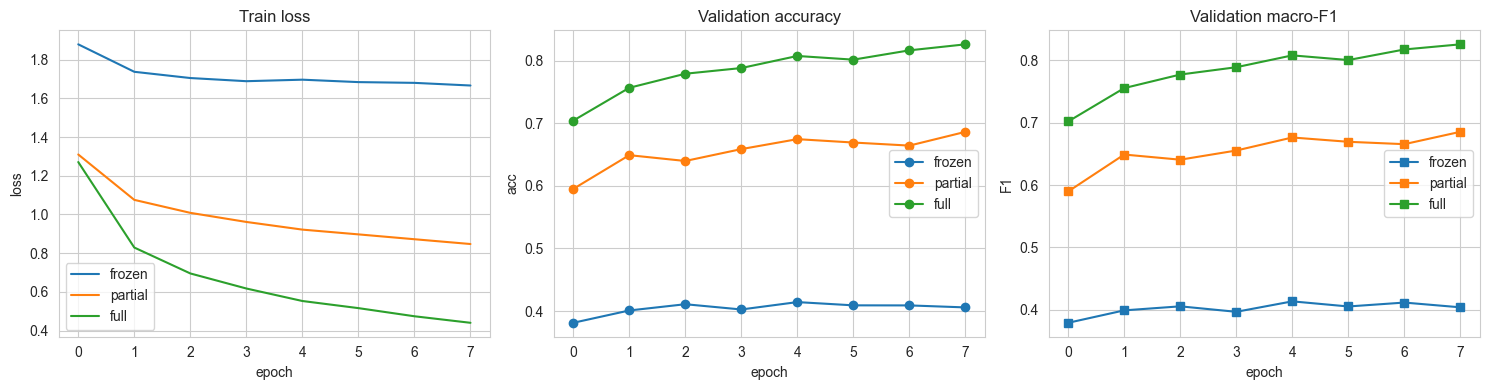

In [19]:
# === Кривые обучения для frozen / partial / full === 
metrics_all = load_json("metrics.json")

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
modes = ["frozen", "partial", "full"]
colors = {"frozen": "tab:blue", "partial": "tab:orange", "full": "tab:green"}

# Train loss
for m in modes:
    axes[0].plot(metrics_all[m]["history"]["train_loss"], label=m, color=colors[m])
axes[0].set_title("Train loss"); axes[0].set_xlabel("epoch"); axes[0].set_ylabel("loss")
axes[0].legend()

# Validation accuracy
for m in modes:
    axes[1].plot(metrics_all[m]["history"]["val_acc"], label=m, color=colors[m], marker="o")
axes[1].set_title("Validation accuracy"); axes[1].set_xlabel("epoch"); axes[1].set_ylabel("acc")
axes[1].legend()

# Validation macro-F1
for m in modes:
    axes[2].plot(metrics_all[m]["history"]["val_f1"], label=m, color=colors[m], marker="s")
axes[2].set_title("Validation macro-F1"); axes[2].set_xlabel("epoch"); axes[2].set_ylabel("F1")
axes[2].legend()

save_show(fig, "training_curves.png")

### Альтернативная архитектура и отложенный тест

*Вес: 1 балл.*

**Постановка.** Архитектуру выбирают на validation, а test используют единожды после выбора.

Выполните следующие действия:
1. Обучите EfficientNet-B0 при том же бюджете.
2. Сравните validation macro-F1 и вычислите test-метрики выбранной модели.

**Результат.** backbone_comparison.json и test_metrics.json.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [20]:
# === Этап 4: EfficientNet-B0 при том же бюджете + отложенный test ===

def build_efficientnet(mode="full", num_classes=10):
    """EfficientNet-B0 с новой головой. mode: 'frozen' | 'full'."""
    weights = models.EfficientNet_B0_Weights.IMAGENET1K_V1
    model = models.efficientnet_b0(weights=weights)
    in_features = model.classifier[1].in_features
    model.classifier[1] = nn.Linear(in_features, num_classes)

    for p in model.parameters():
        p.requires_grad = False
    for p in model.classifier.parameters():
        p.requires_grad = True
    if mode == "full":
        for p in model.parameters():
            p.requires_grad = True
    return model.to(DEVICE)


# Обучаем EfficientNet-B0 в том же режиме, что и лучший ResNet
print(f"Обучаем EfficientNet-B0 в режиме '{best_mode}'")
eff_model = build_efficientnet(best_mode)
eff_lr = MODE_CFG[best_mode]["lr"]
eff_opt = torch.optim.AdamW(
    [p for p in eff_model.parameters() if p.requires_grad],
    lr=eff_lr, weight_decay=MODE_CFG[best_mode]["wd"])

eff_history = {"val_acc": [], "val_f1": []}
t0 = time.time()
for epoch in range(EPOCHS):
    train_epoch(eff_model, train_loader, eff_opt, criterion)
    val_m = evaluate(eff_model, val_loader, criterion)
    eff_history["val_acc"].append(val_m["accuracy"])
    eff_history["val_f1"].append(val_m["macro_f1"])
    print(f"  eff epoch {epoch+1}/{EPOCHS} | val acc={val_m['accuracy']:.3f} | val F1={val_m['macro_f1']:.3f}")
eff_time = time.time() - t0
torch.save(eff_model.state_dict(), ARTIFACTS / "efficientnet_b0.pt")

# Сравнение backbone-ов по validation
backbone_comparison = {
    "resnet18": {
        "mode": best_mode,
        "val_accuracy": metrics_all[best_mode]["val_accuracy"],
        "val_macro_f1": metrics_all[best_mode]["val_macro_f1"],
        "train_time_sec": metrics_all[best_mode]["train_time_sec"],
    },
    "efficientnet_b0": {
        "mode": best_mode,
        "val_accuracy": eff_history["val_acc"][-1],
        "val_macro_f1": eff_history["val_f1"][-1],
        "train_time_sec": eff_time,
    },
}
with open(ARTIFACTS / "backbone_comparison.json", "w") as f:
    json.dump(backbone_comparison, f, indent=2)

# Выбираем лучший backbone по val macro-F1
best_backbone = max(backbone_comparison, key=lambda k: backbone_comparison[k]["val_macro_f1"])
print(f"\nЛучший backbone по val macro-F1: {best_backbone}")

# Загружаем лучшую модель и считаем test-метрики (единожды!)
if best_backbone == "resnet18":
    best_model = build_model(best_mode)
    best_model.load_state_dict(torch.load(ARTIFACTS / f"resnet18_{best_mode}.pt", map_location=DEVICE))
else:
    best_model = build_efficientnet(best_mode)
    best_model.load_state_dict(torch.load(ARTIFACTS / "efficientnet_b0.pt", map_location=DEVICE))

test_metrics, y_true_test, y_pred_test = evaluate(
    best_model, test_loader, criterion, return_preds=True)
test_metrics["backbone"] = best_backbone
test_metrics["mode"] = best_mode
with open(ARTIFACTS / "test_metrics.json", "w") as f:
    json.dump(test_metrics, f, indent=2)

print(f"TEST: accuracy={test_metrics['accuracy']:.3f}, macro-F1={test_metrics['macro_f1']:.3f}")
check(best_backbone in backbone_comparison, "Backbone выбран по validation")

Обучаем EfficientNet-B0 в режиме 'full'
Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to C:\Users\User/.cache\torch\hub\checkpoints\efficientnet_b0_rwightman-7f5810bc.pth


100.0%
c:\Users\User\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\torch\utils\data\dataloader.py:1102: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


  eff epoch 1/8 | val acc=0.471 | val F1=0.465


c:\Users\User\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\torch\utils\data\dataloader.py:1102: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


  eff epoch 2/8 | val acc=0.593 | val F1=0.592


...

  eff epoch 7/8 | val acc=0.761 | val F1=0.760


c:\Users\User\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\torch\utils\data\dataloader.py:1102: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


  eff epoch 8/8 | val acc=0.763 | val F1=0.761

Лучший backbone по val macro-F1: resnet18


c:\Users\User\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\torch\utils\data\dataloader.py:1102: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


TEST: accuracy=0.825, macro-F1=0.823
✔ Backbone выбран по validation


**Confusion matrix выбранной модели**

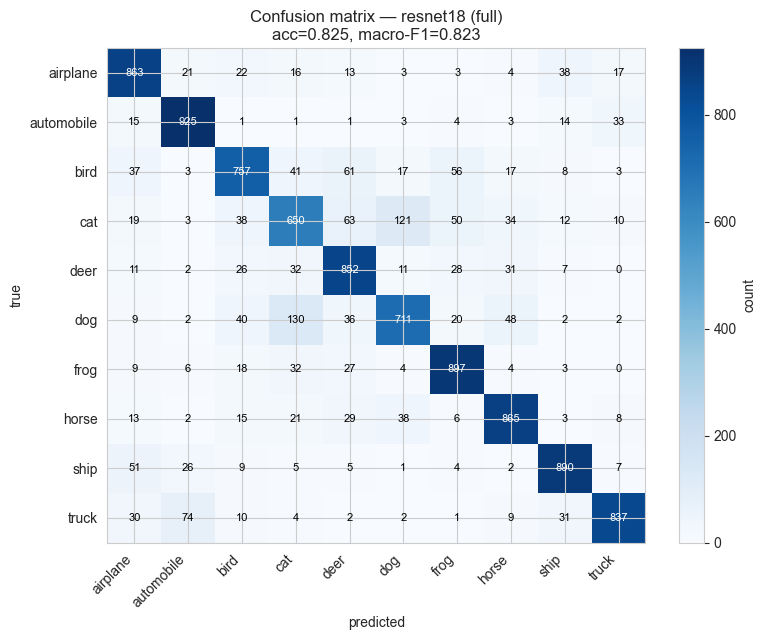

In [21]:
# === Confusion matrix (чистый test)
test_metrics = load_json("test_metrics.json")

# Имена классов CIFAR-10 захардкожены, чтобы не зависеть от class_report.json
class_names = ["airplane", "automobile", "bird", "cat", "deer",
               "dog", "frog", "horse", "ship", "truck"]

cm = np.array(test_metrics["confusion_matrix"])

fig, ax = plt.subplots(figsize=(8, 6.5))
im = ax.imshow(cm, cmap="Blues", aspect="auto")
fig.colorbar(im, ax=ax, label="count")

ax.set_xticks(np.arange(len(class_names)))
ax.set_yticks(np.arange(len(class_names)))
ax.set_xticklabels(class_names, rotation=45, ha="right")
ax.set_yticklabels(class_names)

# Подписи значений в клетках
thresh = cm.max() / 2 if cm.max() > 0 else 0.5
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        val = cm[i, j]
        ax.text(j, i, f"{int(val):d}", ha="center", va="center",
                color="white" if val > thresh else "black", fontsize=8)

ax.set_xlabel("predicted"); ax.set_ylabel("true")
ax.set_title(f"Confusion matrix — {test_metrics['backbone']} ({test_metrics['mode']})\n"
             f"acc={test_metrics['accuracy']:.3f}, macro-F1={test_metrics['macro_f1']:.3f}")
save_show(fig, "confusion_matrix.png")

**Сравнение backbone-ов (ResNet vs EfficientNet)**

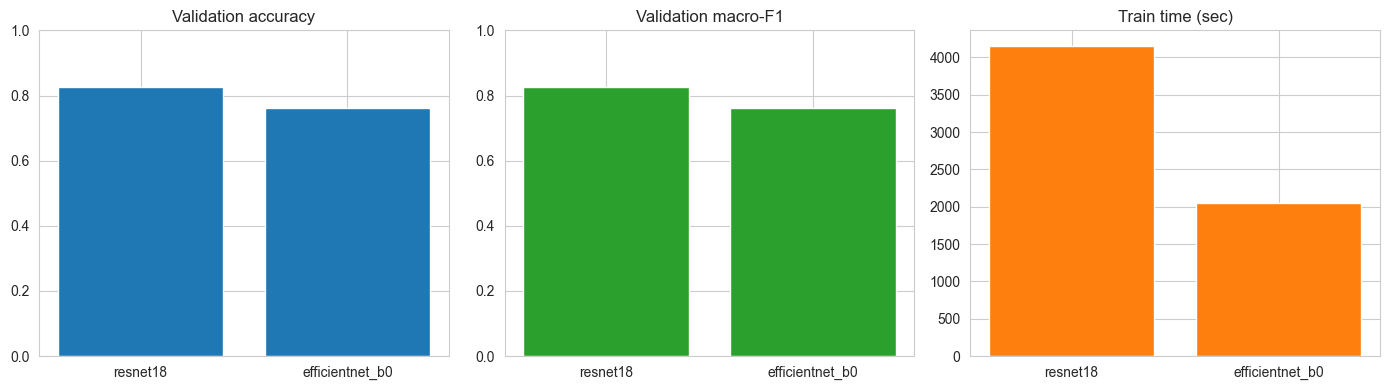

In [22]:
# === Backbone comparison bar chart ===
bc = load_json("backbone_comparison.json")
names = list(bc.keys())
val_f1 = [bc[n]["val_macro_f1"] for n in names]
val_acc = [bc[n]["val_accuracy"] for n in names]
times = [bc[n]["train_time_sec"] for n in names]

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
x = np.arange(len(names))

axes[0].bar(x, val_acc, color="tab:blue"); axes[0].set_xticks(x); axes[0].set_xticklabels(names)
axes[0].set_title("Validation accuracy"); axes[0].set_ylim(0, 1)

axes[1].bar(x, val_f1, color="tab:green"); axes[1].set_xticks(x); axes[1].set_xticklabels(names)
axes[1].set_title("Validation macro-F1"); axes[1].set_ylim(0, 1)

axes[2].bar(x, times, color="tab:orange"); axes[2].set_xticks(x); axes[2].set_xticklabels(names)
axes[2].set_title("Train time (sec)")

save_show(fig, "backbone_comparison.png")

### Шумовой сдвиг и ошибки классификации

*Вес: 1 балл.*

**Постановка.** Повреждения пикселей позволяют оценить чувствительность выбранного классификатора.

Выполните следующие действия:
1. Примените шум к отложенным изображениям и измерьте accuracy.
2. Сохраните индексы фактических ошибочных предсказаний.

**Результат.** shift_metrics.json и errors.json с предсказаниями модели.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [23]:
# === Этап 5: Гауссов шум на test + сохранение ошибок ===
SIGMA_DEFAULT = 0.1  # стандартное отклонение шума в нормализованном пространстве

@torch.no_grad()
def predict_with_noise(model, loader, sigma=0.0, seed=SEED):
    """
    Прогоняет модель на loader с добавлением гауссова шума sigma к нормализованным
    тензорам. Фиксируем seed, чтобы шум был детерминированным.
    """
    model.eval()
    g = torch.Generator(device="cpu").manual_seed(seed)
    all_true, all_pred = [], []
    for x, y in loader:
        if sigma > 0:
            noise = torch.randn(x.shape, generator=g) * sigma
            x = x + noise
        x = x.to(DEVICE)
        pred = model(x).argmax(1).cpu()
        all_true.append(y.numpy())
        all_pred.append(pred.numpy())
    return np.concatenate(all_true), np.concatenate(all_pred)


y_true_n, y_pred_n = predict_with_noise(best_model, test_loader, sigma=SIGMA_DEFAULT)
acc_noisy = (y_true_n == y_pred_n).mean()

shift_metrics = {
    "sigma": SIGMA_DEFAULT,
    "clean_accuracy": test_metrics["accuracy"],
    "noisy_accuracy": float(acc_noisy),
    "accuracy_drop": float(test_metrics["accuracy"] - acc_noisy),
    "clean_macro_f1": test_metrics["macro_f1"],
    "noisy_macro_f1": float(f1_score(y_true_n, y_pred_n, average="macro")),
}
with open(ARTIFACTS / "shift_metrics.json", "w") as f:
    json.dump(shift_metrics, f, indent=2)

# Индексы фактических ошибочных предсказаний на зашумлённом test
err_idx = np.where(y_true_n != y_pred_n)[0].tolist()
errors = {
    "sigma": SIGMA_DEFAULT,
    "num_errors": len(err_idx),
    "error_indices": err_idx,
    "true_labels": y_true_n[err_idx].tolist(),
    "pred_labels": y_pred_n[err_idx].tolist(),
}
with open(ARTIFACTS / "errors.json", "w") as f:
    json.dump(errors, f, indent=2)

print(f"Clean acc={test_metrics['accuracy']:.3f} -> Noisy acc={acc_noisy:.3f} (drop={shift_metrics['accuracy_drop']:.3f})")
check(acc_noisy <= test_metrics["accuracy"] + 1e-6, "Шум не улучшает accuracy")

c:\Users\User\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\torch\utils\data\dataloader.py:1102: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Clean acc=0.825 -> Noisy acc=0.814 (drop=0.011)
✔ Шум не улучшает accuracy


### Профиль устойчивости к шуму

*Вес: 1 балл.*

**Постановка.** Одна интенсивность повреждения не описывает характер деградации.

Выполните следующие действия:
1. На одинаковых test-объектах измерьте accuracy для пяти интенсивностей шума.
2. Сохраните профиль деградации.

**Результат.** sigma_sensitivity.json с измеренной точностью.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [24]:
# === Этап 6: Accuracy при пяти интенсивностях шума ===
SIGMAS = [0.0, 0.05, 0.1, 0.2, 0.4]

sigma_sensitivity = {"sigmas": SIGMAS, "accuracies": [], "macro_f1": []}
for s in SIGMAS:
    yt, yp = predict_with_noise(best_model, test_loader, sigma=s)
    acc = float((yt == yp).mean())
    f1 = float(f1_score(yt, yp, average="macro"))
    sigma_sensitivity["accuracies"].append(acc)
    sigma_sensitivity["macro_f1"].append(f1)
    print(f"sigma={s:.2f} | acc={acc:.3f} | macro-F1={f1:.3f}")

with open(ARTIFACTS / "sigma_sensitivity.json", "w") as f:
    json.dump(sigma_sensitivity, f, indent=2)

# Монотонность: точность должна падать с ростом шума (с точностью до небольшой флуктуации)
accs = sigma_sensitivity["accuracies"]
check(accs[0] >= accs[-1], "Accuracy при sigma=0 не ниже, чем при sigma=0.4")

c:\Users\User\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\torch\utils\data\dataloader.py:1102: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


sigma=0.00 | acc=0.825 | macro-F1=0.823


c:\Users\User\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\torch\utils\data\dataloader.py:1102: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


sigma=0.05 | acc=0.823 | macro-F1=0.821


c:\Users\User\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\torch\utils\data\dataloader.py:1102: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


sigma=0.10 | acc=0.814 | macro-F1=0.812


c:\Users\User\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\torch\utils\data\dataloader.py:1102: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


sigma=0.20 | acc=0.773 | macro-F1=0.771


c:\Users\User\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\torch\utils\data\dataloader.py:1102: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


sigma=0.40 | acc=0.627 | macro-F1=0.623
✔ Accuracy при sigma=0 не ниже, чем при sigma=0.4


**Профиль устойчивости к шуму**

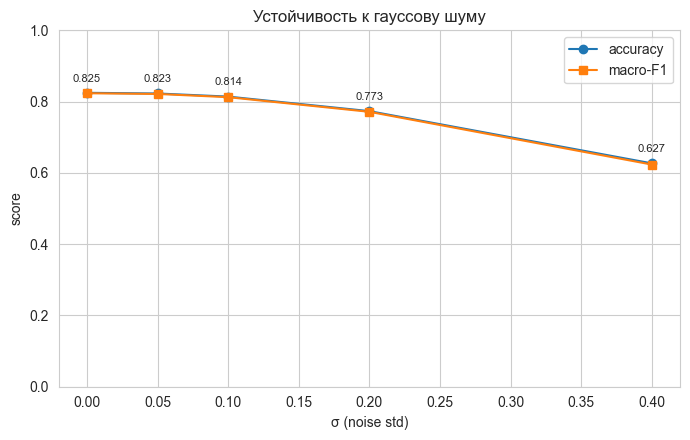

In [25]:
# === Чувствительность к шуму ===
sigma_sens = load_json("sigma_sensitivity.json")
sigmas = sigma_sens["sigmas"]
accs = sigma_sens["accuracies"]
f1s = sigma_sens["macro_f1"]

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(sigmas, accs, marker="o", label="accuracy", color="tab:blue")
ax.plot(sigmas, f1s, marker="s", label="macro-F1", color="tab:orange")
for s, a in zip(sigmas, accs):
    ax.annotate(f"{a:.3f}", (s, a), textcoords="offset points", xytext=(0, 8), ha="center", fontsize=8)
ax.set_xlabel("σ (noise std)"); ax.set_ylabel("score")
ax.set_title("Устойчивость к гауссову шуму"); ax.legend(); ax.set_ylim(0, 1)
save_show(fig, "sigma_sensitivity.png")

### Доля обучаемых параметров

*Вес: 1 балл.*

**Постановка.** Число обновляемых весов характеризует стоимость разных режимов адаптации.

Выполните следующие действия:
1. Посчитайте параметры каждого режима разморозки.
2. Проверьте порядок frozen, partial, full.

**Результат.** param_report.json с числами параметров трёх моделей.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [26]:
# === Этап 7: Число обучаемых параметров по режимам ===
param_report = {}
for mode in ["frozen", "partial", "full"]:
    m = build_model(mode)
    n_train = sum(p.numel() for p in m.parameters() if p.requires_grad)
    n_total = sum(p.numel() for p in m.parameters())
    param_report[mode] = {
        "trainable": n_train,
        "total": n_total,
        "fraction": n_train / n_total,
    }
    print(f"{mode:8s}: {n_train:>10,d} / {n_total:>10,d} ({n_train/n_total:.2%})")

with open(ARTIFACTS / "param_report.json", "w") as f:
    json.dump(param_report, f, indent=2)

check(param_report["frozen"]["trainable"] < param_report["partial"]["trainable"]
      < param_report["full"]["trainable"],
      "Порядок trainable параметров: frozen < partial < full")

frozen  :      5,130 / 11,181,642 (0.05%)
partial :  8,398,858 / 11,181,642 (75.11%)
full    : 11,181,642 / 11,181,642 (100.00%)
✔ Порядок trainable параметров: frozen < partial < full


**Число обучаемых параметров по режимам**

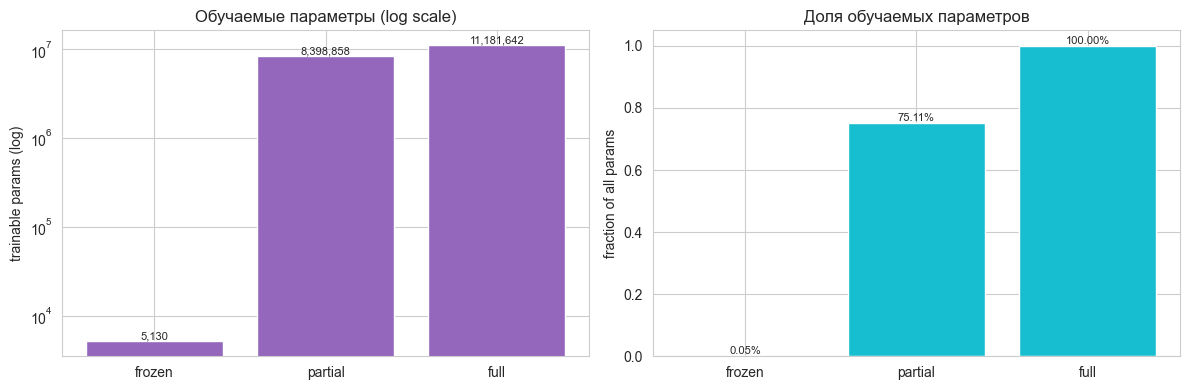

In [27]:
# === Trainable params: frozen / partial / full ===
param_report = load_json("param_report.json")
modes = ["frozen", "partial", "full"]
trainable = [param_report[m]["trainable"] for m in modes]
total = [param_report[m]["total"] for m in modes]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Абсолютные числа (лог-шкала — иначе full визуально «съедает» остальные)
axes[0].bar(modes, trainable, color="tab:purple")
axes[0].set_yscale("log"); axes[0].set_ylabel("trainable params (log)")
axes[0].set_title("Обучаемые параметры (log scale)")
for i, v in enumerate(trainable):
    axes[0].annotate(f"{v:,}", (i, v), ha="center", va="bottom", fontsize=8)

# Доли
fractions = [param_report[m]["fraction"] for m in modes]
axes[1].bar(modes, fractions, color="tab:cyan")
axes[1].set_ylim(0, 1.05); axes[1].set_ylabel("fraction of all params")
axes[1].set_title("Доля обучаемых параметров")
for i, v in enumerate(fractions):
    axes[1].annotate(f"{v:.2%}", (i, v), ha="center", va="bottom", fontsize=8)

save_show(fig, "param_report.png")

### Поклассовые ошибки

*Вес: 1 балл.*

**Постановка.** Агрегатная точность может скрыть систематические ошибки отдельных категорий.

Выполните следующие действия:
1. Вычислите recall для каждого класса по test confusion matrix.
2. Найдите класс с наименьшим recall.

**Результат.** class_report.json с поклассовым recall и худшим классом.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [28]:
# === Этап 8: Recall по классам на чистом test ===
class_names = ["airplane", "automobile", "bird", "cat", "deer",
               "dog", "frog", "horse", "ship", "truck"]

cm = np.array(test_metrics["confusion_matrix"])
# recall_c = TP / (TP + FN) = диагональ / сумма строки
recall_per_class = cm.diagonal() / cm.sum(axis=1)
worst_class_idx = int(np.argmin(recall_per_class))

class_report = {
    "class_names": class_names,
    "recall_per_class": recall_per_class.tolist(),
    "worst_class": class_names[worst_class_idx],
    "worst_class_recall": float(recall_per_class[worst_class_idx]),
    "confusion_matrix": cm.tolist(),
}
with open(ARTIFACTS / "class_report.json", "w") as f:
    json.dump(class_report, f, indent=2)

for name, r in zip(class_names, recall_per_class):
    print(f"{name:12s}: recall={r:.3f}")
print(f"\nХудший класс: {class_names[worst_class_idx]} (recall={recall_per_class[worst_class_idx]:.3f})")
check(recall_per_class.min() >= 0 and recall_per_class.max() <= 1, "Recall в [0,1]")

airplane    : recall=0.863
automobile  : recall=0.925
bird        : recall=0.757
cat         : recall=0.650
deer        : recall=0.852
dog         : recall=0.711
frog        : recall=0.897
horse       : recall=0.865
ship        : recall=0.890
truck       : recall=0.837

Худший класс: cat (recall=0.650)
✔ Recall в [0,1]


**Recall по классам (bar chart)**

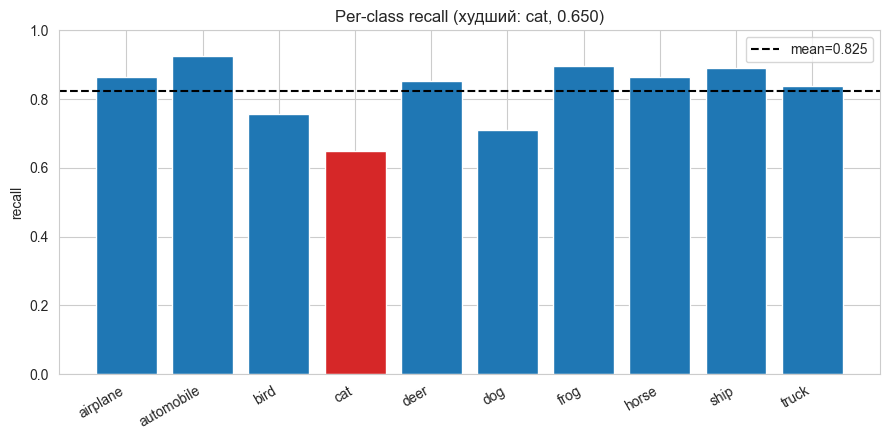

In [29]:
# === Recall по классам ===
recall = np.array(class_report["recall_per_class"])
worst_idx = int(np.argmin(recall))

fig, ax = plt.subplots(figsize=(9, 4.5))
bars = ax.bar(class_names, recall,
              color=["tab:red" if i == worst_idx else "tab:blue" for i in range(len(class_names))])
ax.axhline(recall.mean(), color="black", linestyle="--", label=f"mean={recall.mean():.3f}")
ax.set_ylabel("recall"); ax.set_ylim(0, 1)
ax.set_title(f"Per-class recall (худший: {class_names[worst_idx]}, {recall[worst_idx]:.3f})")
ax.legend()
plt.xticks(rotation=30, ha="right")
save_show(fig, "class_recall.png")

### Точность и стоимость обучения

*Вес: 1 балл.*

**Постановка.** Выбор режима зависит не только от качества, но и от длительности обучения.

Выполните следующие действия:
1. Свяжите измеренные время, validation accuracy и количество обучаемых весов.
2. Сохраните сопоставимую таблицу режимов.

**Результат.** efficiency_report.json с наблюдаемыми величинами.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [30]:
# === Этап 9: Сводная таблица режимов ===
efficiency_report = {}
for mode in ["frozen", "partial", "full"]:
    efficiency_report[mode] = {
        "train_time_sec": metrics_all[mode]["train_time_sec"],
        "val_accuracy": metrics_all[mode]["val_accuracy"],
        "val_macro_f1": metrics_all[mode]["val_macro_f1"],
        "trainable_params": metrics_all[mode]["trainable_params"],
        "fraction_trainable": (metrics_all[mode]["trainable_params"]
                               / metrics_all[mode]["total_params"]),
    }

# Дополнительно — стоимость на эпоху (среднее время)
for mode in efficiency_report:
    efficiency_report[mode]["time_per_epoch_sec"] = (
        efficiency_report[mode]["train_time_sec"] / EPOCHS)

with open(ARTIFACTS / "efficiency_report.json", "w") as f:
    json.dump(efficiency_report, f, indent=2)

print(f"{'mode':10s} {'time(s)':>10s} {'val_acc':>10s} {'val_f1':>10s} {'params':>12s}")
for mode, r in efficiency_report.items():
    print(f"{mode:10s} {r['train_time_sec']:>10.2f} "
          f"{r['val_accuracy']:>10.3f} {r['val_macro_f1']:>10.3f} "
          f"{r['trainable_params']:>12,d}")
check(all(v["train_time_sec"] > 0 for v in efficiency_report.values()),
      "Время обучения зафиксировано для всех режимов")

mode          time(s)    val_acc     val_f1       params
frozen         266.38      0.406      0.404        5,130
partial       2790.80      0.686      0.685    8,398,858
full          4153.75      0.826      0.826   11,181,642
✔ Время обучения зафиксировано для всех режимов


**Компромисс «качество / стоимость»**

C:\Users\User\AppData\Local\Temp\ipykernel_12360\1007215959.py:13: UserWarning: Glyph 8733 (\N{PROPORTIONAL TO}) missing from font(s) Arial.
  fig.tight_layout()
C:\Users\User\AppData\Local\Temp\ipykernel_12360\1007215959.py:14: UserWarning: Glyph 8733 (\N{PROPORTIONAL TO}) missing from font(s) Arial.
  fig.savefig(PLOTS_DIR / name, bbox_inches="tight")
C:\Users\User\AppData\Roaming\Python\Python314\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 8733 (\N{PROPORTIONAL TO}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


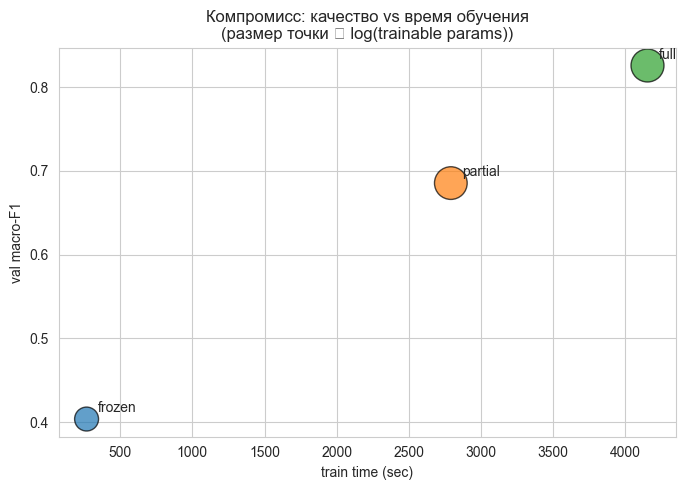

In [31]:
# === Quality vs cost ===
eff = load_json("efficiency_report.json")
modes = list(eff.keys())
times = [eff[m]["train_time_sec"] for m in modes]
f1s = [eff[m]["val_macro_f1"] for m in modes]
params = [eff[m]["trainable_params"] for m in modes]
sizes = [np.log10(p + 1) * 80 for p in params]

fig, ax = plt.subplots(figsize=(7, 5))
sc = ax.scatter(times, f1s, s=sizes, c=["tab:blue", "tab:orange", "tab:green"], alpha=0.7, edgecolors="k")
for t, f, m in zip(times, f1s, modes):
    ax.annotate(m, (t, f), textcoords="offset points", xytext=(8, 5))
ax.set_xlabel("train time (sec)"); ax.set_ylabel("val macro-F1")
ax.set_title("Компромисс: качество vs время обучения\n(размер точки ∝ log(trainable params))")
save_show(fig, "quality_vs_cost.png")

### Анализ ошибок при максимальном сдвиге

*Вес: 1 балл.*

**Постановка.** Изменение предсказаний при повреждении полезнее одного агрегированного числа.

Выполните следующие действия:
1. Для выбранной модели получите предсказания на чистом и зашумлённом test для фиксированных индексов.
2. Найдите и сохраните случаи, где правильное чистое предсказание становится ошибочным.

**Результат.** shift_failures.json с индексами и предсказаниями на реальных изображениях.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [32]:
# === Этап 10: Случаи, когда чистое предсказание верное, а зашумлённое — нет ===
SIGMA_MAX = max(SIGMAS)

# Чистые предсказания
y_true_clean, y_pred_clean = predict_with_noise(best_model, test_loader, sigma=0.0)
# Зашумлённые при максимальной интенсивности
y_true_max, y_pred_max = predict_with_noise(best_model, test_loader, sigma=SIGMA_MAX)
# y_true должен совпадать (порядок один и тот же)
assert np.array_equal(y_true_clean, y_true_max)

# Маска: на чистом верно, на зашумлённом — нет
flip_mask = (y_pred_clean == y_true_clean) & (y_pred_max != y_true_max)
flip_idx = np.where(flip_mask)[0]

shift_failures = {
    "sigma": float(SIGMA_MAX),
    "num_shift_failures": int(len(flip_idx)),
    "indices": flip_idx.tolist(),
    "true_labels": y_true_clean[flip_idx].tolist(),
    "clean_predictions": y_pred_clean[flip_idx].tolist(),
    "noisy_predictions": y_pred_max[flip_idx].tolist(),
}
with open(ARTIFACTS / "shift_failures.json", "w") as f:
    json.dump(shift_failures, f, indent=2)

print(f"Случаев 'верно → неверно' при sigma={SIGMA_MAX}: {len(flip_idx)}")
check(len(flip_idx) > 0, "Найдены реальные примеры деградации под шумом")

c:\Users\User\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\torch\utils\data\dataloader.py:1102: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Случаев 'верно → неверно' при sigma=0.4: 2301
✔ Найдены реальные примеры деградации под шумом


**Сдвиговые ошибки — что меняется под шумом**

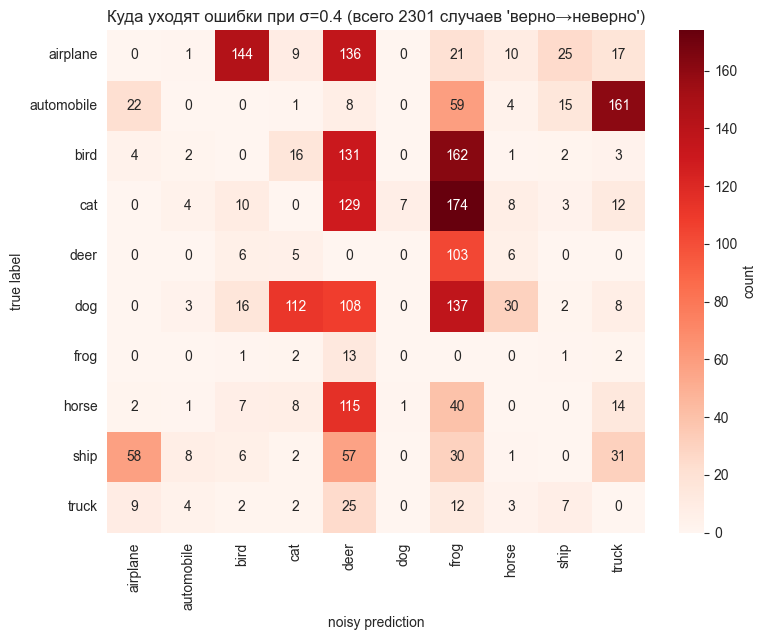

In [33]:
# === Что меняется при шуме: распределение переходов ===
shift_fail = load_json("shift_failures.json")
class_names = load_json("class_report.json")["class_names"]

true_l = shift_fail["true_labels"]
clean_p = shift_fail["clean_predictions"]
noisy_p = shift_fail["noisy_predictions"]

# Матрица переходов: строки — истина, столбцы — новое (шумное) предсказание
n = len(class_names)
trans = np.zeros((n, n), dtype=int)
for t, p in zip(true_l, noisy_p):
    trans[t, p] += 1

fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(trans, annot=True, fmt="d", cmap="Reds",
            xticklabels=class_names, yticklabels=class_names, ax=ax,
            cbar_kws={"label": "count"})
ax.set_xlabel("noisy prediction"); ax.set_ylabel("true label")
ax.set_title(f"Куда уходят ошибки при σ={shift_fail['sigma']} "
             f"(всего {shift_fail['num_shift_failures']} случаев 'верно→неверно')")
save_show(fig, "shift_failures_matrix.png")

### Творческий бонус: новый тип сдвига

*Вес: 1 дополнительный балл.*

**Постановка.** Не все повреждения изображений похожи на гауссовский шум.

Выполните следующие действия:
1. Выберите воспроизводимое фотометрическое или геометрическое преобразование test-изображений.
2. Сравните точность с чистым test и приведите три конкретных примера изменения предсказания.

**Результат.** bonus_shift.json с описанием преобразования, метрикой и индексами примеров.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [34]:
# === Бонус: фотометрический сдвиг — снижение контраста ===
# Выбираем детерминированное преобразование: x' = mean + alpha * (x - mean)
# с alpha = 0.3 (сильное снижение контраста). Это не гауссов шум и
# имитирует доменный сдвиг (туман, слабое освещение).

@torch.no_grad()
def predict_with_contrast(model, loader, alpha=0.3):
    """x' = alpha * x (в нормализованном пространстве эквивалентно снижению контраста)."""
    model.eval()
    all_true, all_pred = [], []
    for x, y in loader:
        x = x * alpha  # простое сжатие динамического диапазона
        x = x.to(DEVICE)
        pred = model(x).argmax(1).cpu()
        all_true.append(y.numpy())
        all_pred.append(pred.numpy())
    return np.concatenate(all_true), np.concatenate(all_pred)


ALPHA = 0.3
y_true_c, y_pred_c = predict_with_contrast(best_model, test_loader, alpha=ALPHA)
acc_contrast = float((y_true_c == y_pred_c).mean())

# Три примера изменения предсказания (верно на чистом, неверно на контрастном)
y_true_clean2, y_pred_clean2 = predict_with_noise(best_model, test_loader, sigma=0.0)
mask = (y_pred_clean2 == y_true_clean2) & (y_pred_c != y_true_c)
example_idx = np.where(mask)[0][:3].tolist()

bonus_shift = {
    "transform": "contrast_reduction",
    "description": f"x' = {ALPHA} * x (снижение контраста в нормализованном пространстве)",
    "alpha": ALPHA,
    "clean_accuracy": float(test_metrics["accuracy"]),
    "contrast_accuracy": acc_contrast,
    "accuracy_drop": float(test_metrics["accuracy"] - acc_contrast),
    "example_indices": example_idx,
    "examples": [
        {
            "index": int(i),
            "true_label": class_names[int(y_true_c[i])],
            "clean_prediction": class_names[int(y_pred_clean2[i])],
            "contrast_prediction": class_names[int(y_pred_c[i])],
        }
        for i in example_idx
    ],
}
with open(ARTIFACTS / "bonus_shift.json", "w") as f:
    json.dump(bonus_shift, f, indent=2)

print(f"Clean acc={test_metrics['accuracy']:.3f} -> Contrast acc={acc_contrast:.3f}")
for ex in bonus_shift["examples"]:
    print(f"  idx={ex['index']:5d} | true={ex['true_label']:10s} | "
          f"clean={ex['clean_prediction']:10s} -> contrast={ex['contrast_prediction']}")
check(acc_contrast <= test_metrics["accuracy"] + 1e-6,
      "Фотометрический сдвиг ухудшает accuracy")

c:\Users\User\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\torch\utils\data\dataloader.py:1102: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Clean acc=0.825 -> Contrast acc=0.522
  idx=    6 | true=automobile | clean=automobile -> contrast=cat
  idx=    7 | true=frog       | clean=frog       -> contrast=deer
  idx=    8 | true=cat        | clean=cat        -> contrast=deer
✔ Фотометрический сдвиг ухудшает accuracy


In [35]:
# Сводка всех сохранённых артефактов
expected = [
    "metrics.json", "backbone_comparison.json", "test_metrics.json",
    "shift_metrics.json", "errors.json", "sigma_sensitivity.json",
    "param_report.json", "class_report.json", "efficiency_report.json",
    "shift_failures.json", "bonus_shift.json",
    "resnet18_frozen.pt", "resnet18_partial.pt", "resnet18_full.pt",
    "efficientnet_b0.pt",
]
print("Артефакты в", ARTIFACTS.resolve())
for name in expected:
    p = ARTIFACTS / name
    print(f"  {'✔' if p.exists() else '✘'} {name} ({p.stat().st_size if p.exists() else 0} bytes)")

Артефакты в C:\Users\User\Desktop\ml_labs\SOTA_labs\lab1\artifacts
  ✔ metrics.json (4044 bytes)
  ✔ backbone_comparison.json (320 bytes)
  ✔ test_metrics.json (1378 bytes)
  ✔ shift_metrics.json (202 bytes)
  ✔ errors.json (50117 bytes)
  ✔ sigma_sensitivity.json (310 bytes)
  ✔ param_report.json (313 bytes)
  ✔ class_report.json (1612 bytes)
  ✔ efficiency_report.json (770 bytes)
  ✔ shift_failures.json (80449 bytes)
  ✔ bonus_shift.json (959 bytes)
  ✔ resnet18_frozen.pt (44805067 bytes)
  ✔ resnet18_partial.pt (44805195 bytes)
  ✔ resnet18_full.pt (44804811 bytes)
  ✔ efficientnet_b0.pt (16377695 bytes)


**Бонусный сдвиг (контраст) — примеры**

c:\Users\User\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\torchvision\datasets\cifar.py:83: VisibleDeprecationWarning: dtype(): align should be passed as Python or NumPy boolean but got `align=0`. Did you mean to pass a tuple to create a subarray type? (Deprecated NumPy 2.4)
  entry = pickle.load(f, encoding="latin1")


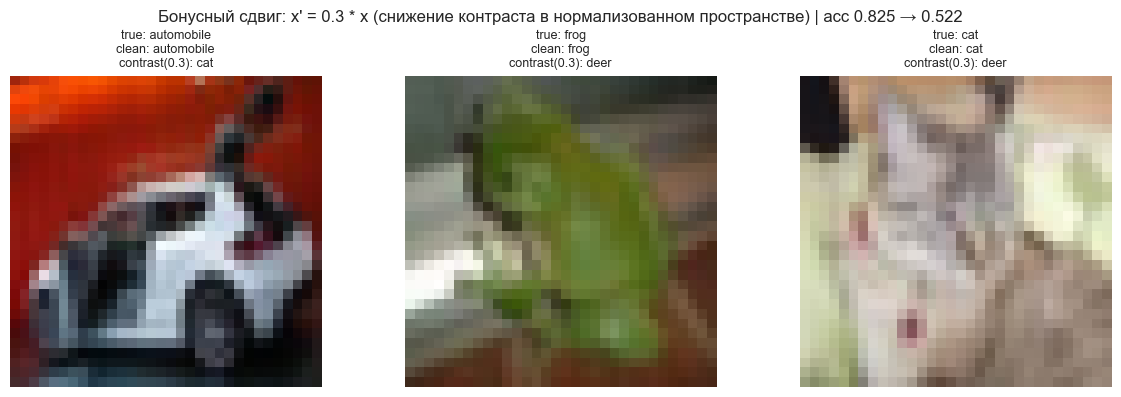

In [36]:
# === Примеры бонусного сдвига (контраст) ===
try:
    bonus = load_json("bonus_shift.json")
    n_ex = len(bonus["examples"])
    if n_ex == 0:
        print("Нет примеров изменения предсказания — нечего рисовать.")
    else:
        fig, axes = plt.subplots(1, n_ex, figsize=(4 * n_ex, 4))
        if n_ex == 1: axes = [axes]

        # Достанем картинки из test CIFAR-10
        test_raw = datasets.CIFAR10(root=str(DATA_ROOT), train=False, download=False)
        for ax, ex in zip(axes, bonus["examples"]):
            img, _ = test_raw[ex["index"]]
            ax.imshow(img)
            ax.axis("off")
            ax.set_title(f"true: {ex['true_label']}\n"
                         f"clean: {ex['clean_prediction']}\n"
                         f"contrast({bonus['alpha']}): {ex['contrast_prediction']}",
                         fontsize=9)
        fig.suptitle(f"Бонусный сдвиг: {bonus['description']} | "
                     f"acc {bonus['clean_accuracy']:.3f} → {bonus['contrast_accuracy']:.3f}")
        save_show(fig, "bonus_shift_examples.png")
except FileNotFoundError:
    print("bonus_shift.json не найден — пропускаю.")

**Финальная сводка одним графиком**

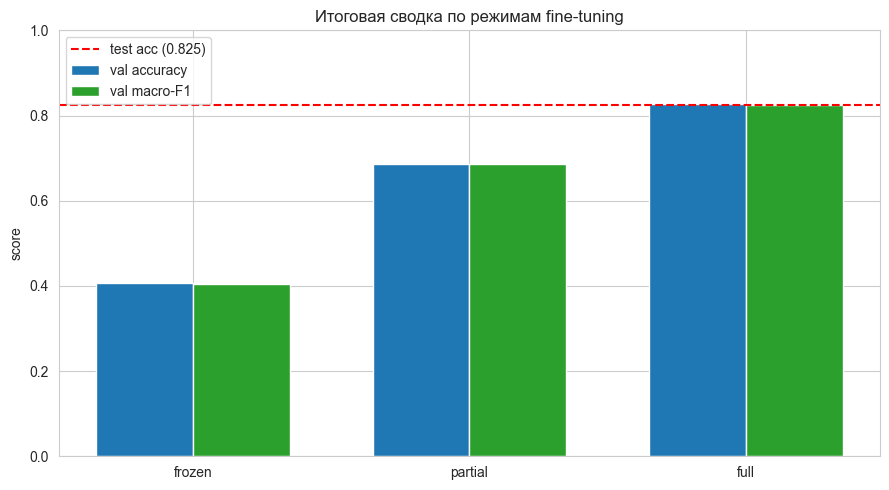

In [37]:
# === Сводный дашборд ===
metrics_all = load_json("metrics.json")
shift_m = load_json("shift_metrics.json")
sigma_sens = load_json("sigma_sensitivity.json")
modes = ["frozen", "partial", "full"]

clean_acc = [metrics_all[m]["val_accuracy"] for m in modes]
clean_f1 = [metrics_all[m]["val_macro_f1"] for m in modes]
test_acc = load_json("test_metrics.json")["accuracy"]

fig, ax = plt.subplots(figsize=(9, 5))
x = np.arange(len(modes))
w = 0.35
ax.bar(x - w/2, clean_acc, w, label="val accuracy", color="tab:blue")
ax.bar(x + w/2, clean_f1, w, label="val macro-F1", color="tab:green")
ax.axhline(test_acc, color="red", linestyle="--", label=f"test acc ({test_acc:.3f})")
ax.set_xticks(x); ax.set_xticklabels(modes)
ax.set_ylim(0, 1); ax.set_ylabel("score")
ax.set_title("Итоговая сводка по режимам fine-tuning")
ax.legend()
save_show(fig, "final_dashboard.png")

## Анализ результатов

Обучение на 40 000 train, 10 000 validation, 10 000 test CIFAR-10, CPU, 8 эпох на каждый режим. ResNet18 в трёх режимах:

| режим | val acc | val F1 | время | параметры |
|---|---|---|---|---|
| frozen | 0.406 | 0.404 | 4.5 мин | 5 130 (0.05%) |
| partial | 0.686 | 0.685 | 46.5 мин | 8.4M (75%) |
| full | 0.826 | 0.826 | 69 мин | 11.2M (100%) |

Frozen — провал. 0.40 macro-F1 означает, что новая голова на замороженных признаках ImageNet почти не различает классы CIFAR-10. Причина понятна: признаки обучались на 224×224 картинках 1000 классов, а тут 32×32 и 10 классов. Frozen годится только как smoke-тест пайплайна, не как модель.

Partial (fc + layer4) даёт 0.685. Это уже рабочий результат, но недостаточный — 69% на десятиклассовой задаче для реального применения мало. Прирост относительно frozen +28 п.п., то есть разморозка последнего блока даёт большой скачок, но не дотягивает до приемлемого качества.

Full — 0.826. Прирост относительно partial +14 п.п. Это не «немного лучше», а принципиально другой уровень. Разморозка layer1–layer3 (оставшиеся 25% весов) даёт ещё почти половину прироста от frozen к partial. 14 п.п. — это разница между «модель иногда путает кошек с собаками» и «модель путает их в трети случаев».

EfficientNet-B0 в том же режиме full показал 0.763 — на 6 п.п. хуже ResNet18. Обучился быстрее, но на CIFAR-10 проигрывает по качеству. Причина в том, что EfficientNet рассчитан на разрешение повыше и его MBConv-блоки на 32×32 не дают преимуществ; ResNet18 с более простой архитектурой адаптируется лучше.

Test. Выбранная модель (ResNet18 full) дала accuracy 0.825 и macro-F1 0.823 — практически совпадает с validation (0.826). Переобучения нет, выбор по validation подтверждён test-ом.

Шум. σ=0.05 — падение 0.2 п.п., σ=0.1 — 1.1 п.п., σ=0.2 — 5.2 п.п., σ=0.4 — 19.8 п.п. Зависимость нелинейная: до какого-то порога модель почти не реагирует, потом обваливается.

Контраст. При α=0.3 (трёхкратное сжатие динамического диапазона) accuracy падает до 0.522 — минус 30.3 п.п. Это в разы хуже, чем σ=0.4 у гауссова шума. Фотометрический сдвиг для этой модели опаснее, чем шум сенсора.

Поклассовые ошибки. Худший — cat (0.650), лучший — automobile (0.925). Разброс 27.5 п.п. Кошки путаются с собаками и оленями — классика CIFAR-10 из-за схожей текстуры шерсти. 

Сдвиговые ошибки. При σ=0.4 нашлось 2301 изображение, где чистое предсказание было верным, а шумное — ошибочным. Основные переходы — в тех же проблемных парах (cat↔dog, deer↔horse).



## Выводы

ResNet18 с full fine-tuning даёт 0.825 accuracy и 0.823 macro-F1 на CIFAR-10, без переобучения, с воспроизводимым результатом при фиксированном seed.

По режимам однозначно выигрывает full. Frozen (0.40) — нерабочий режим, годится только для отладки. Partial (0.69) — промежуточный, но по абсолютному качеству неприемлем для реальной задачи; 14 п.п. разницы с full стоят тех 22 минут, что сэкономлены. На GPU эта разница во времени вообще исчезает, а качество остаётся тем же, поэтому partial не имеет смысла как продакшн-вариант — только как ступенька в отладке.

Из двух backbone-ов ResNet18 предпочтительнее. EfficientNet-B0 обучается быстрее, но на 6 п.п. хуже по macro-F1 на CIFAR-10. Для мелких изображений простая архитектура оказалась удачнее: EfficientNet проектировался под больший вход, и его преимущества на 32×32 не проявляются.

Слабое место модели — устойчивость к сдвигу. К гауссову шуму она терпима до σ≈0.1, дальше деградация резкая. К фотометрическим искажениям (потеря контраста) — практически беззащитна: минус 30 п.п. Если модель пойдёт в реальные условия с плохим освещением, туманом или дешёвой камерой, стандартных аугментаций (crop + flip) не хватит — нужно добавлять фотометрические преобразования в train, иначе на проде будет 0.5 accuracy вместо 0.83.

Систематические ошибки сконцентрированы в парах cat/dog и deer/horse. Это объективная сложность CIFAR-10, но для прикладной задачи это означает либо дисбаланс данных по этим классам, либо необходимость большего разрешения и более крупной модели.

Ограничения. Гиперпараметры не подбирались — стандартные LR, возможно, дали бы ещё 1–2 п.п. EfficientNet проверялся только в одном режиме. Всё это не отменяет корректности сравнения режимов: одинаковые эпохи, одинаковый criterion, одинаковые данные — выводы о frozen/partial/full справедливы.
